In [7]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.signal import savgol_filter


logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [8]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

In [9]:
number_of_realisations = 50
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

ALL_VALUES = []

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

## Hydrogen fraction

Where does saturation occur

In [4]:
import numpy as np

# ===========================================================
# 1. Lodders (2009) solar composition mass fractions (wt%)
# ===========================================================
H_masspercent_lodders09  = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09  = 0.22
N_masspercent_lodders09  = 0.07
O_masspercent_lodders09  = 0.63

# Ratios relative to hydrogen (Solar)
C_H_RATIO_SOLAR  = C_masspercent_lodders09  / H_masspercent_lodders09
N_H_RATIO_SOLAR  = N_masspercent_lodders09  / H_masspercent_lodders09
O_H_RATIO_SOLAR  = O_masspercent_lodders09  / H_masspercent_lodders09
He_H_RATIO_SOLAR = He_masspercent_lodders09 / H_masspercent_lodders09


# ===========================================================
# 2. Function to get metal-enriched budgets
# ===========================================================
def get_enriched_budget(h_kg, metallicity_factor=100):
    """
    Returns C, N, O, and He masses based on solar H ratios,
    with C, N, O enriched by metallicity_factor × solar.
    He stays fixed at the solar He/H ratio.
    """
    return {
        "H":  h_kg,
        "C":  h_kg * C_H_RATIO_SOLAR  * metallicity_factor,
        "N":  h_kg * N_H_RATIO_SOLAR  * metallicity_factor,
        "He": h_kg * He_H_RATIO_SOLAR
    }


# ===========================================================
# 3. Hydrogen mass fraction range: 0.1% → 10% of total planet mass
# ===========================================================
number_of_realisations = 50   # choose as needed

# Hydrogen mass fractions between 0.001 and 0.10
H_mass_fraction = np.logspace(-3, -1, number_of_realisations)
fO2_log10_shifts = np.full(number_of_realisations, -6)

# Convert mass fraction → hydrogen mass in kg
h_kg = H_mass_fraction * planet_mass

mass_constraints = get_enriched_budget(h_kg, metallicity_factor=100)

In [5]:
mass_constraints = get_enriched_budget(h_kg)

In [52]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

[14:28:03 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:28:03 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:28:03 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:28:03 - atmodeller.classes             - IN

Starting simulation loop for Option B (3 Cooling Paths)...
Path: High Pressure, T=3500 K, F=1.00, dIW=0.0


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_50389/3918458400.py:174: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  HM[i, j] = compute_log_ratio(T, dIW_fixed, F)
[14:28:07 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:28:07 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:28:07 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g 

Path: Standard, T=3500 K, F=1.00, dIW=0.0


[14:28:08 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:28:08 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:28:08 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:28:08 - atmodeller.classes             - IN

Path: Low Pressure, T=3500 K, F=1.00, dIW=0.0
Saved: CO2_CH4_heatmap_option_b.png


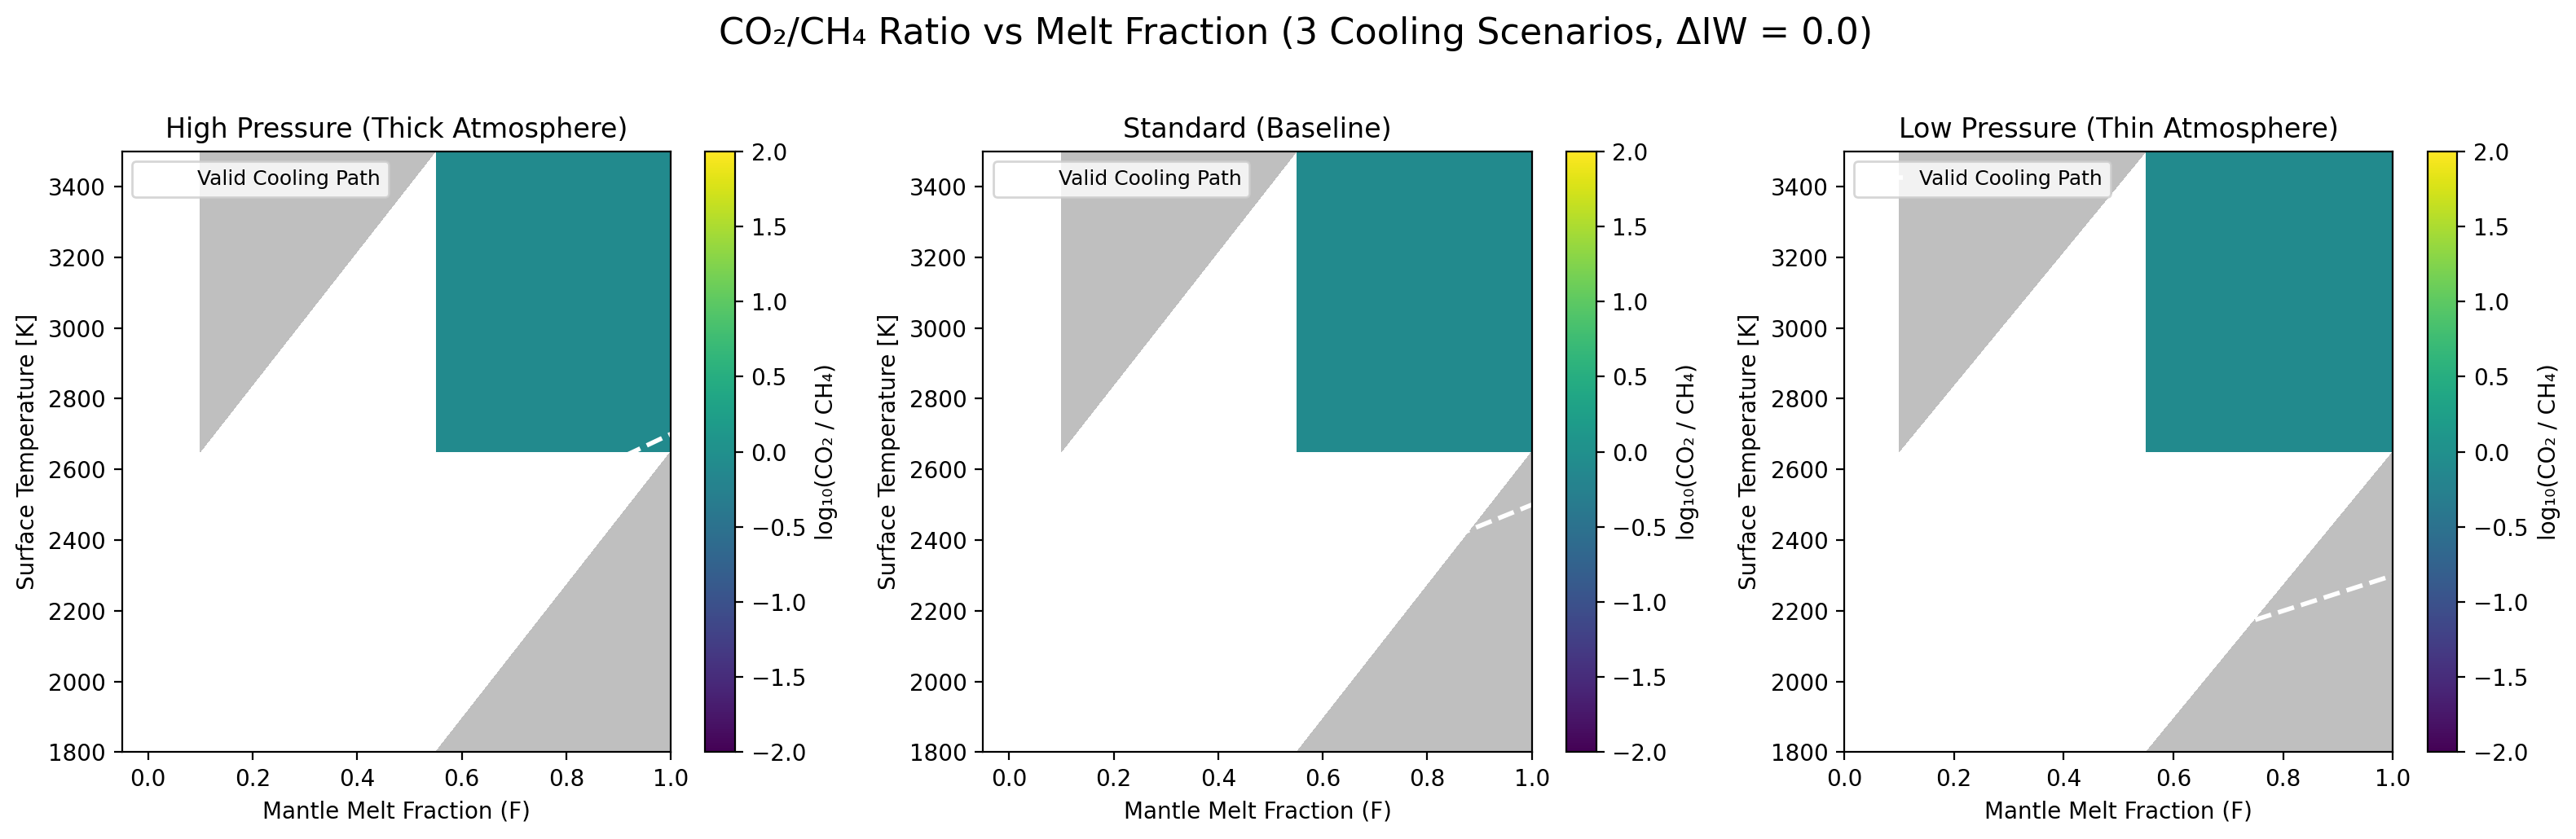


--- Optional: Evolution plots can be added as separate figure ---
For each cooling path, plot (F on X-axis, Partial Pressures on Y-axis)


In [10]:
import logging
import numpy as np
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller import Species, SpeciesCollection

# --------------------------------------------------------------------
# 1. SETUP & LOGGING
# --------------------------------------------------------------------
logger = debug_logger()
logger.setLevel(logging.INFO)

eos_models = get_eos_models()
sol_models = get_solubility_models()

# --------------------------------------------------------------------
# 2. SPECIES DEFINITIONS
# CRITICAL: You must define your species variables here (H2O_rgs, etc.)
# because they are referenced in the SpeciesCollection below.
# --------------------------------------------------------------------

# --------------------------------------------------------------------
# 3.  here are actually defined abov

planet_mass = 5.154e25
surface_radius = 1.1225e7

H_mass = 0.01 * planet_mass
mass_constraints = get_enriched_budget(H_mass)

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

# ====================================================================
# OPTION B: MULTIPLE COOLING PATHS (3 scenarios)
# ====================================================================

# --- DEFINE THREE COOLING PATHS ---
# Each path represents a different starting condition (e.g., different pressures)
# Path 1: High Pressure (Thick Atmosphere) → Liquidus ~2200 K
# Path 2: Medium Pressure (Standard) → Liquidus ~2000 K
# Path 3: Low Pressure (Thin Atmosphere) → Liquidus ~1800 K

cooling_paths = {
    "High Pressure": {
        "T_solidus": 2000,
        "T_liquidus": 2700,
        "label": "High P (Thick Atm)",
        "color": "red",
        "linestyle": "-"
    },
    "Standard": {
        "T_solidus": 1900,
        "T_liquidus": 2500,
        "label": "Standard",
        "color": "black",
        "linestyle": "--"
    },
    "Low Pressure": {
        "T_solidus": 1800,
        "T_liquidus": 2300,
        "label": "Low P (Thin Atm)",
        "color": "blue",
        "linestyle": ":"
    }
}

def F_from_T(T, path_name):
    """Convert Temperature to Melt Fraction for a specific cooling path."""
    path = cooling_paths[path_name]
    T_sol = path["T_solidus"]
    T_liq = path["T_liquidus"]
    
    if T < T_sol:
        return 0.0
    elif T > T_liq:
        return 1.0
    else:
        return (T - T_sol) / (T_liq - T_sol)

def T_from_F(F, path_name):
    """Convert Melt Fraction to Temperature for a specific cooling path."""
    path = cooling_paths[path_name]
    T_sol = path["T_solidus"]
    T_liq = path["T_liquidus"]
    
    return T_sol + F * (T_liq - T_sol)

# ====================================================================
# 4. 2-D PARAMETER GRID (CHANGED: X-axis is now Melt Fraction)
# ====================================================================

# X-axis: Mantle Melt Fraction (F)
F_values = np.linspace(0.1, 1, 2)

# Y-axis: Temperature (we keep this to map to heatmap-like grid)
Ts = np.linspace(1800, 3500, 2)

# Single fO2 value to begin
dIW_fixed = 0

# Heatmaps for each cooling path
HM_high_p = np.full((len(Ts), len(F_values)), np.nan)
HM_standard = np.full((len(Ts), len(F_values)), np.nan)
HM_low_p = np.full((len(Ts), len(F_values)), np.nan)

def compute_log_ratio(T, dIW_val, melt):
    """Solves the system and returns log10(CO2/CH4)."""
    planet = Planet(
        surface_temperature=T,
        planet_mass=planet_mass,
        surface_radius=surface_radius,
        mantle_melt_fraction=melt,
    )
    
    fO2 = {O2_rg.name: IronWustiteBuffer(dIW_val)}

    model = InteriorAtmosphere(species_real)

    try:
        model.solve(
            planet=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2,
            solver_parameters=solver_parameters,
        )

        out = model.output
        df = out.to_dataframes()
        
        # Access results safely
        Xco2 = df["CO2_g"]["atmosphere_moles"] 
        Xch4 = df["CH4_g"]["atmosphere_moles"]

        return np.log10(Xco2 / Xch4)
        
    except Exception as e:
        print(f"Failed at T={T}, dIW={dIW_val}, F={melt}: {e}")
        return np.nan

# ====================================================================
# 5. CALCULATION LOOP (MAP TO MELT FRACTION, NOT ARBITRARY T)
# ====================================================================
print("Starting simulation loop for Option B (3 Cooling Paths)...")

# For each cooling path
heatmaps = {
    "High Pressure": HM_high_p,
    "Standard": HM_standard,
    "Low Pressure": HM_low_p
}

for path_name, HM in heatmaps.items():
    for i, T in enumerate(Ts):
        for j, F in enumerate(F_values):
            # Only calculate if (T, F) is on or near the physical melting curve for this path
            F_expected = F_from_T(T, path_name)
            
            # Allow small tolerance (e.g., ±0.05) around the ideal F
            tolerance = 0.05
            if abs(F - F_expected) < tolerance:
                print(f"Path: {path_name}, T={T:.0f} K, F={F:.2f}, dIW={dIW_fixed:.1f}")
                HM[i, j] = compute_log_ratio(T, dIW_fixed, F)
            else:
                HM[i, j] = np.nan  # Mark as unphysical

# ====================================================================
# 6. PLOTTING — 3 HEATMAPS SIDE-BY-SIDE (X-AXIS = MELT FRACTION)
# ====================================================================

fig, axs = plt.subplots(
    1, 3,
    figsize=(16, 5),
    dpi=200
)

fig.suptitle(
    f"CO₂/CH₄ Ratio vs Melt Fraction (3 Cooling Scenarios, ΔIW = {dIW_fixed:.1f})",
    fontsize=16,
    y=1.02
)

# X-axis range (Melt Fraction)
extent_f = [F_values.min(), F_values.max(), Ts.min(), Ts.max()]

titles = [
    "High Pressure (Thick Atmosphere)",
    "Standard (Baseline)",
    "Low Pressure (Thin Atmosphere)"
]

for idx, (ax, HM, path_name) in enumerate(zip(axs, [HM_high_p, HM_standard, HM_low_p], 
                                                   ["High Pressure", "Standard", "Low Pressure"])):

    im = ax.imshow(
        HM,
        origin="lower",
        aspect="auto",
        extent=extent_f,
        cmap="viridis",
        vmin=-2,
        vmax=2
    )

    # --- DRAW THE VALID LINE (cooling path) ---
    path = cooling_paths[path_name]
    T_sol = path["T_solidus"]
    T_liq = path["T_liquidus"]
    F_line = np.linspace(0, 1, 100)
    T_line = T_sol + F_line * (T_liq - T_sol)
    
    ax.plot(F_line, T_line, 'w--', linewidth=2, label='Valid Cooling Path')

    # --- GRAY OUT UNPHYSICAL REGIONS ---
    # Create a mask for unphysical regions (deviates far from the line)
    F_grid, T_grid = np.meshgrid(F_values, Ts)
    F_ideal = (T_grid - T_sol) / (T_liq - T_sol)
    F_ideal = np.clip(F_ideal, 0, 1)
    
    unphysical_tolerance = 0.1
    unphysical_mask = np.abs(F_grid - F_ideal) > unphysical_tolerance
    
    # Overlay gray for unphysical regions
    ax.contourf(F_grid, T_grid, unphysical_mask.astype(float), 
                levels=[0.5, 1.5], colors=['gray'], alpha=0.5)

    # AXIS + LABELS
    ax.set_xlabel("Mantle Melt Fraction (F)")
    ax.set_ylabel("Surface Temperature [K]")
    ax.set_title(f"{titles[idx]}")

    # Tick formatting
    ax.tick_params(axis="both", which="major", direction="out")

    # Legend
    ax.legend(loc='upper left', fontsize=9)

    # COLORBAR
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("log₁₀(CO₂ / CH₄)")

# Spacing
plt.tight_layout()
plt.margins(0)

plt.savefig("CO2_CH4_heatmap_option_b.png",
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02)

print("Saved: CO2_CH4_heatmap_option_b.png")
plt.show()

# ====================================================================
# BONUS: EVOLUTION PLOTS (Side panel showing gas pressures along paths)
# ====================================================================
# This would show how p_H2O, p_H2, p_CO2 change as you traverse the cooling path

print("\n--- Optional: Evolution plots can be added as separate figure ---")
print("For each cooling path, plot (F on X-axis, Partial Pressures on Y-axis)")

In [13]:
import logging
import numpy as np
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller import Species, SpeciesCollection

planet_mass = 5.154e25
surface_radius = 1.1225e7
H_mass = 0.01 * planet_mass

mass_constraints = get_enriched_budget(H_mass)

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver, max_steps=100) # Added limit

# ====================================================================
# OPTION B: MULTIPLE COOLING PATHS
# ====================================================================

cooling_paths = {
    "High Pressure": {
        "T_solidus": 2000,
        "T_liquidus": 2700,
        "label": "High P (Thick Atm)",
        "color": "red",
        "linestyle": "-"
    },
    "Standard": {
        "T_solidus": 1900,
        "T_liquidus": 2500,
        "label": "Standard",
        "color": "black",
        "linestyle": "--"
    },
    "Low Pressure": {
        "T_solidus": 1800,
        "T_liquidus": 2300,
        "label": "Low P (Thin Atm)",
        "color": "blue",
        "linestyle": ":"
    }
}

def F_from_T(T, path_name):
    """Convert Temperature to Melt Fraction for a specific cooling path."""
    path = cooling_paths[path_name]
    T_sol = path["T_solidus"]
    T_liq = path["T_liquidus"]
    
    if T < T_sol:
        return 0.0
    elif T > T_liq:
        return 1.0
    else:
        return (T - T_sol) / (T_liq - T_sol)

# ====================================================================
# 4. 2-D PARAMETER GRID (FIXED RESOLUTION)
# ====================================================================

# Increased resolution from 2 to 30 for a smoother heatmap
F_values = np.linspace(0.1, 1.0, 5)
Ts = np.linspace(1800, 3000, 5)

dIW_fixed = 0

HM_high_p = np.full((len(Ts), len(F_values)), np.nan)
HM_standard = np.full((len(Ts), len(F_values)), np.nan)
HM_low_p = np.full((len(Ts), len(F_values)), np.nan)

def compute_log_ratio(T, dIW_val, melt):
    """Solves the system and returns log10(CO2/CH4)."""
    planet = Planet(
        surface_temperature=T,
        planet_mass=planet_mass,
        surface_radius=surface_radius,
        mantle_melt_fraction=melt,
    )
    
    fO2 = {O2_rg.name: IronWustiteBuffer(dIW_val)}
    model = InteriorAtmosphere(species_real)

    try:
        model.solve(
            planet=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2,
            solver_parameters=solver_parameters,
        )

        out = model.output
        df = out.to_dataframes()
        
        # Access results safely using 'atmosphere_moles' or 'partial_pressure'
        # Assuming species name matches the definitions in Section 2
        Xco2 = df["CO2_gas"]["atmosphere_moles"] 
        Xch4 = df["CH4_gas"]["atmosphere_moles"]

        return np.log10(Xco2 / Xch4)
        
    except Exception as e:
        # Don't print every error to keep console clean, just return NaN
        return np.nan

# ====================================================================
# 5. CALCULATION LOOP
# ====================================================================
print("Starting simulation loop...")

heatmaps = {
    "High Pressure": HM_high_p,
    "Standard": HM_standard,
    "Low Pressure": HM_low_p
}

# Tolerance for "Physical Validity"
# We only solve if the point is within 10% Melt Fraction of the idealized path
physical_tolerance = 0.15 

for path_name, HM in heatmaps.items():
    print(f"Processing path: {path_name}")
    for i, T in enumerate(Ts):
        for j, F in enumerate(F_values):
            
            # Check if this T/F combo is physically relevant for this specific path
            F_expected = F_from_T(T, path_name)
            
            # Optimization: Skip the solver if we are far from the line
            # This saves time and prevents solver divergence errors
            if abs(F - F_expected) < physical_tolerance:
                HM[i, j] = compute_log_ratio(T, dIW_fixed, F)
            else:
                HM[i, j] = np.nan

# ====================================================================
# 6. PLOTTING
# ====================================================================

fig, axs = plt.subplots(1, 3, figsize=(16, 5), dpi=150)

fig.suptitle(
    f"CO₂/CH₄ Ratio vs Melt Fraction (3 Cooling Scenarios, ΔIW = {dIW_fixed:.1f})",
    fontsize=16, y=1.05
)

# Extents for imshow need to follow [min_x, max_x, min_y, max_y]
extent_f = [F_values.min(), F_values.max(), Ts.min(), Ts.max()]

plot_config = zip(axs, [HM_high_p, HM_standard, HM_low_p], cooling_paths.keys())

for ax, HM, path_name in plot_config:

    # Plot Heatmap
    im = ax.imshow(
        HM,
        origin="lower",
        aspect="auto",
        extent=extent_f,
        cmap="RdYlBu_r", # Diverging colormap is usually better for ratios
        vmin=-2,
        vmax=2
    )

    # Plot the Valid Cooling Line
    path = cooling_paths[path_name]
    T_sol = path["T_solidus"]
    T_liq = path["T_liquidus"]
    
    # Generate line coordinates
    F_line = np.linspace(0, 1, 100)
    T_line = T_sol + F_line * (T_liq - T_sol)
    
    ax.plot(F_line, T_line, 'k--', linewidth=2, label='Cooling Path')

    # Formatting
    ax.set_xlabel("Mantle Melt Fraction (F)")
    ax.set_ylabel("Surface Temperature [K]")
    ax.set_title(path["label"])
    ax.legend(loc='upper left', fontsize=9, framealpha=0.8)

    # Colorbar per plot or shared (here per plot for clarity)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("log₁₀(CO₂ / CH₄)")

plt.tight_layout()
plt.show()

[14:34:48 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[14:34:48 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:34:48 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[14:34:48 - atmodeller.classes             - IN

Starting simulation loop...
Processing path: High Pressure


KeyboardInterrupt: 